<a href="https://colab.research.google.com/github/marshallini/Programming-for-AI/blob/main/Portfolio%20Task%209%20-%20Dealing%20With%20Images%20-%20Programming%20For%20AI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dealing With Images
**COLAB Diffusion Example**

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

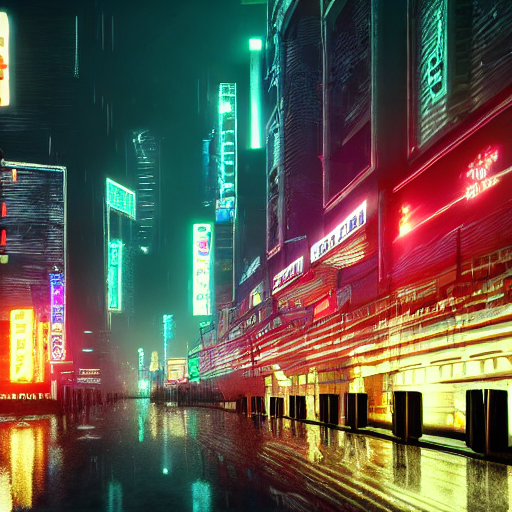

In [ ]:
import torch
import warnings
from diffusers import StableDiffusionPipeline


# 1. Filter out the annoying warnings
# This tells Python: "If a library complains about deprecation, don't show me."
warnings.filterwarnings("ignore")

# 2. Load the model using the correct (but "complaining") parameter
# We MUST use torch_dtype here.
pipe = StableDiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    torch_dtype=torch.float16
)

# 3. Move to GPU
pipe = pipe.to("cuda")

# 4. Run generation
prompt = "A cyberpunk city in heavy rain, neon lights, 8k resolution"
image = pipe(prompt).images[0]
image


# **How to Download the File**

In [ ]:
from google.colab import files # <--- This is the magic import for downloading

# Save the image to Colab's temporary drive
filename = "cyberpunk_city.png"
image.save(filename)

# Trigger the browser download
files.download(filename)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Grid Generation

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Generating 4 images... this might take about 15-20 seconds.


  0%|          | 0/50 [00:00<?, ?it/s]

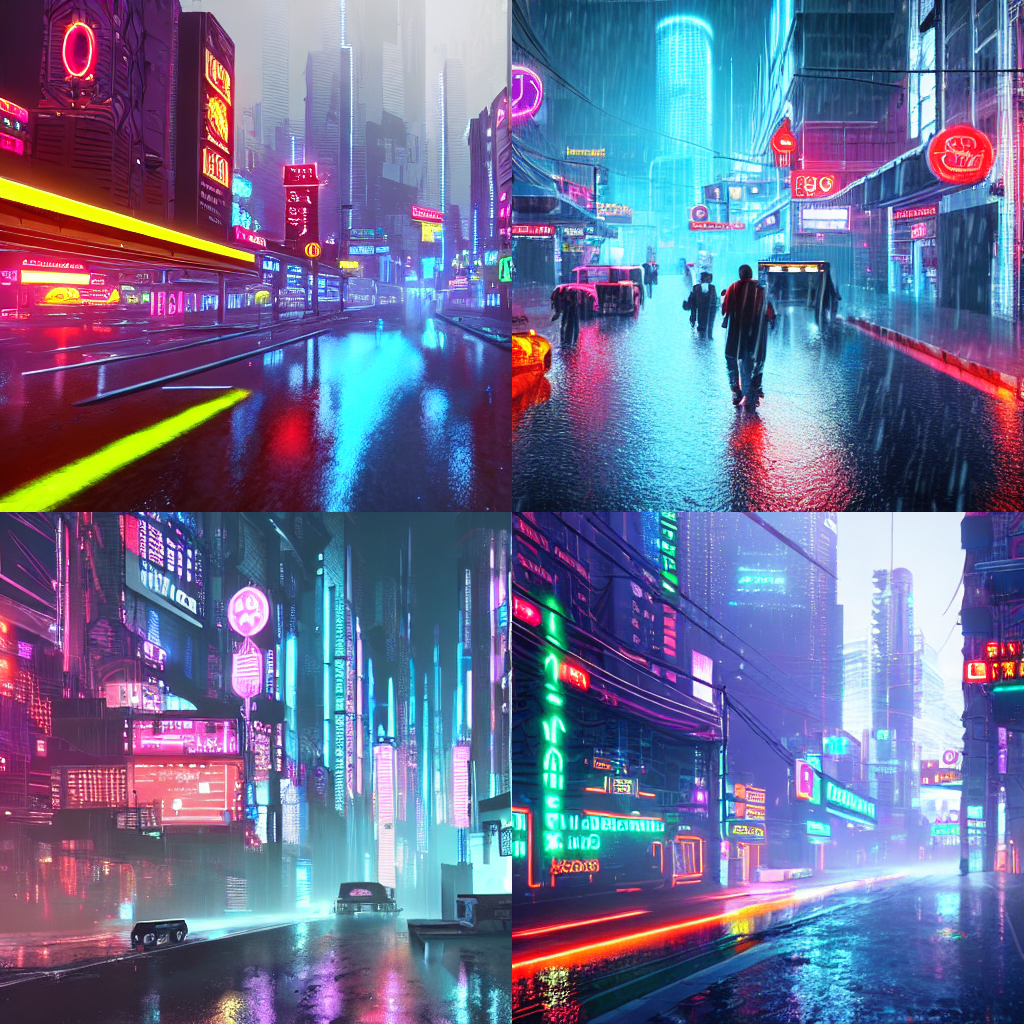

In [ ]:
from PIL import Image
# --- 1. HELPER FUNCTION: Creates a grid from a list of images ---
def make_image_grid(imgs, rows, cols):
    w, h = imgs[0].size
    grid = Image.new('RGB', size=(cols*w, rows*h))
    for i, img in enumerate(imgs):
        grid.paste(img, box=(i%cols*w, i//cols*h))
    return grid
# --- 2. LOAD MODEL ---
pipe = StableDiffusionPipeline.from_pretrained(
    "runwayml/stable-diffusion-v1-5",
    torch_dtype=torch.float16
)
pipe = pipe.to("cuda")
# --- 3. GENERATE 4 IMAGES ---
prompt = "A cyberpunk city in heavy rain, neon lights, 8k resolution"
# We use 'num_images_per_prompt=4' to tell the AI to batch them
print("Generating 4 images... this might take about 15-20 seconds.")
images = pipe(prompt, num_images_per_prompt=4).images

# --- 4. STITCH AND DISPLAY ---
# Create a 2x2 grid
final_grid = make_image_grid(images, rows=2, cols=2)
# Save and Display
final_grid.save("cyberpunk_grid_improved.png")
final_grid


# Realistic Version

model_index.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (126 > 77). Running this sequence through the model will result in indexing errors


  0%|          | 0/30 [00:00<?, ?it/s]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

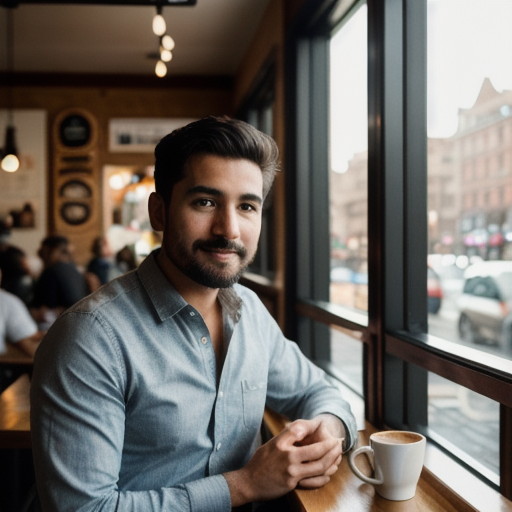

In [ ]:
# swapping the default model for "Realistic Vision"
model_id = "SG161222/Realistic_Vision_V5.1_noVAE"
pipe = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=torch.float16
)
pipe = pipe.to("cuda")
# "Positive" tells it what to draw.
prompt = "raw photo of a man in a coffee shop, natural lighting, 8k uhd, dslr, soft focus, high quality, film grain, Fujifilm XT3"
# "Negative" tells it what to REMOVE (crucial for realism)
neg_prompt = "(deformed iris, deformed pupils, semi-realistic, cgi, 3d, render, sketch, cartoon, drawing, anime), text, cropped, out of frame, worst quality, low quality, jpeg artifacts, ugly, duplicate, morbid, mutilated, extra fingers, mutated hands, poorly drawn hands, poorly drawn face, mutation, deformed, blurry, dehydrated, bad anatomy, bad proportions, extra limbs, cloned face, disfigured, gross proportions, malformed limbs, missing arms, missing legs, extra arms, extra legs, fused fingers, too many fingers, long neck"
# We pass the 'negative_prompt' into the pipe
image = pipe(
    prompt,
    negative_prompt=neg_prompt,
    num_inference_steps=30, # slightly higher steps for better detail
    guidance_scale=6.0      # slightly lower freedom for more realism
).images[0]
image.save("realistic_photo.png")
files.download("realistic_photo.png")
image


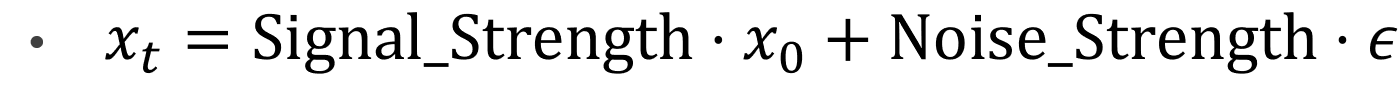